# Analisar 

In [75]:
import numpy as np
import matplotlib.pyplot as plt


In [76]:
datos1 = np.genfromtxt("ejemplo-s11a.txt")
x = datos1[:,0]
y = datos1[:,1]

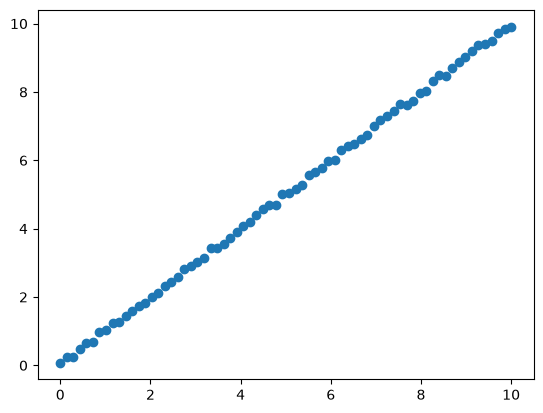

In [77]:
plt.scatter(x,y)

Parece una recta, así que podemos elegir de modelo una recta

In [78]:
a1, a0 = np.polyfit(x,y,1)
print(a1,a0)

0.9982565653897023 0.013945744480063143


In [79]:
res = y-(a0+a1*x)
#print(res)

Algunos son positivos y algunos negativos

In [80]:
print(np.mean(res))

-3.1910981793511643e-15


(0.0, 2.0)

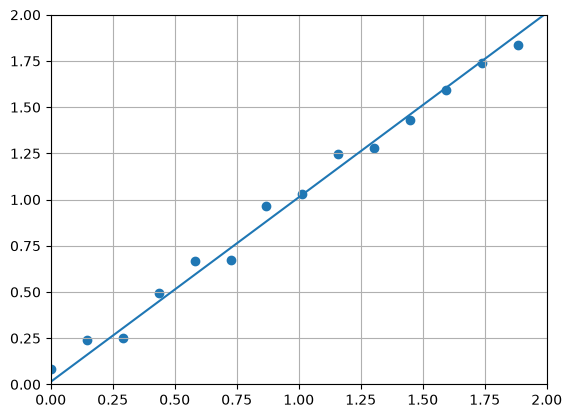

In [81]:
xx = np.linspace(0,10,1000)
plt.plot(xx,a0+a1*xx)
plt.scatter(x,y)
plt.grid(True)
plt.xlim(0,2)
plt.ylim(0,2)

Se ve la distancia desde los datos al ajuste

Mientras que podemos cambiar el y a res para ver los residuous 

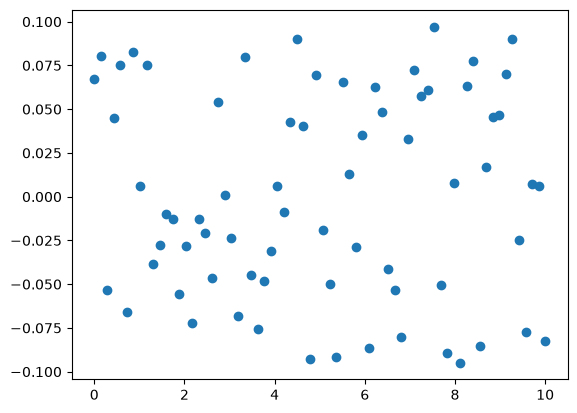

In [82]:
plt.scatter(x,res)


¿que modelo piensan para estos datos? No realmente

In [83]:
datos2 = np.genfromtxt("ejemplo-s11b.txt")
x = datos2[:,0]
y = datos2[:,1]

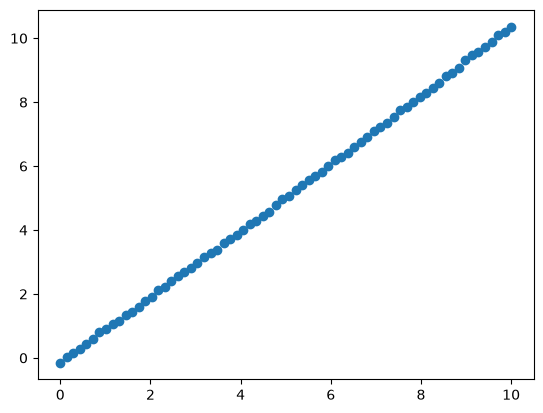

In [84]:
plt.scatter(x,y)

In [85]:
a1, a0 = np.polyfit(x,y,1)
print(a1,a0)

1.0502286700627523 -0.2092290645994724


In [86]:
res = y-(a0+a1*x)
print(res)

[ 0.06222906  0.08594591  0.04666275  0.03937959  0.04309644  0.02481328
  0.09153012  0.03529719  0.05701404 -0.01926912  0.01444772 -0.02983544
 -0.03711859  0.02259825 -0.01468491  0.03503194 -0.01925122  0.02546562
  0.02318246  0.01689931 -0.01638385 -0.03261678  0.00310006  0.00381691
 -0.05646625 -0.00774941 -0.01603256 -0.07131572 -0.04159888 -0.00388204
 -0.07916519 -0.06944835 -0.08573151 -0.03801466  0.00470218 -0.05653075
 -0.00981391  0.00090294 -0.01738022 -0.02566338 -0.06794654 -0.01822969
 -0.00651285 -0.04779601 -0.07707916 -0.04636232 -0.04964548 -0.03092864
  0.01278821 -0.01144472 -0.05972788 -0.00401104  0.03770581  0.00442265
 -0.01486051  0.01185634 -0.02742682 -0.01670998 -0.03099314  0.04772371
 -0.01955945 -0.01084261  0.07787424  0.08364131  0.03135815  0.05207499
  0.04679184  0.11650868  0.05822552  0.07094236]


In [87]:
print(np.mean(res))

-3.621706109616493e-15


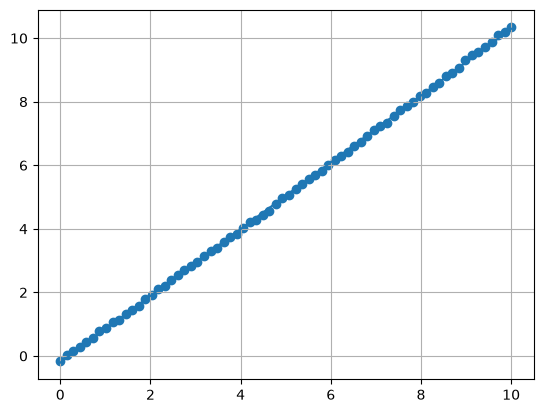

In [88]:
xx = np.linspace(0,10,1000)
plt.plot(xx,a0+a1*xx)
plt.scatter(x,y)
plt.grid(True)
#plt.xlim(0,2)
#plt.ylim(0,2)

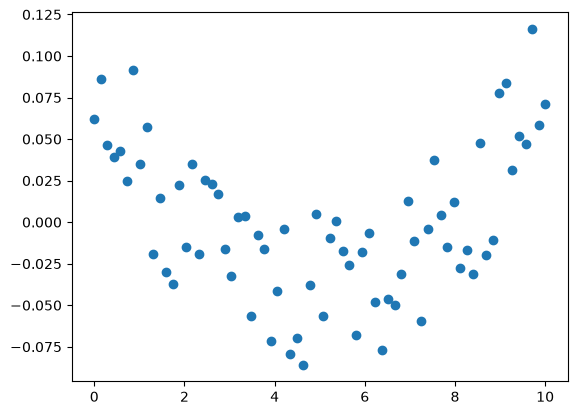

In [89]:
plt.scatter(x,res)

Se puede visualizar que siguen cierto patron, no siendo aleatorios los residuios. Se puede ver si eliges un intervalo en el grafico del ajuste vs datos para verlos más cerca. Pero es mucho más facil de ver si uno hace este grafico de residuos 

Pero si uno ve en este residuos un patron de una parabola

$$
\epsilon = y -f(x)  \quad \implies y=f(x)+\epsilon
$$
$$
\epsilon' =\epsilon - parabola(x) \quad \implies \epsilon = parabola(x) + \epsilon' 
$$
si remplazamos
$$
\epsilon' = y-(f(x)+parabola(x)) \quad \implies y=\epsilon' + (f(x)+parabola(x))

Si yo quiero reescribir la tendencia a los residuos eso es equivalente a ajustarle a los datos originales la suma del ajuste original más el ajuste a los tendencias de los residuos 

Ahora entonces vamos a ajustar una parabola, ya que vimos que los residuos no son aleatorios 

In [90]:
a2pp, a1pp , a0pp = np.polyfit(x,y,2)


In [91]:
plt.plot(xx,np.polyval(np.polyfit(x,y,2)))
plt.scatter(x,y, s=10)
plt.grid(True)

TypeError: polyval() missing 1 required positional argument: 'x'

In [ ]:
res2 = y-(a2pp*x**2+a1pp*x+a0pp)

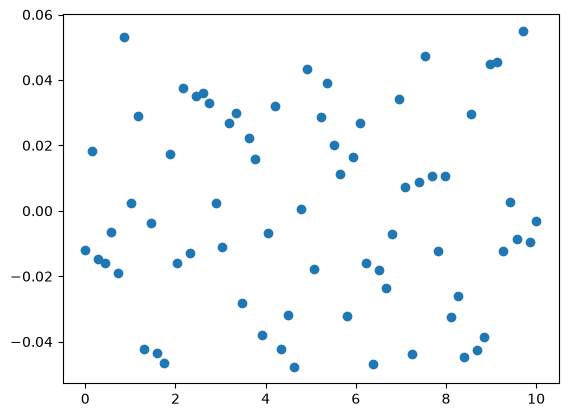

In [ ]:
plt.scatter(x,res2)

# Ahora si son aleatorios!


Ahora como ejercicio, el tercer ejemplo

In [106]:
datos3 = np.genfromtxt("ejemplo-s11c.txt")
x = datos3[:,0]
y = datos3[:,1]

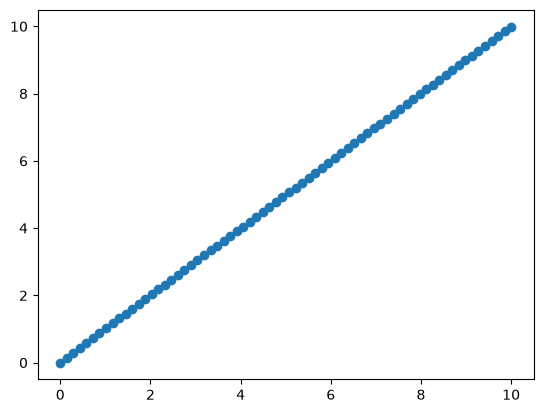

In [107]:
plt.scatter(x,y)

In [108]:
b1,b0 = np.polyfit(x,y,1)

In [109]:
res3 = y - (b1*x+b0)

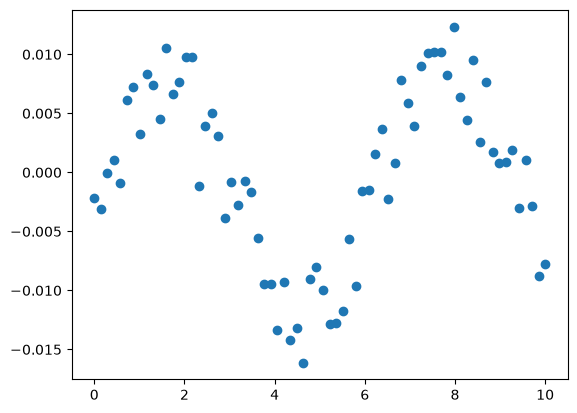

In [110]:
plt.scatter(x,res3)

$$
a*\cos(b*x+c)
$$

Tarea: ajustar el nuevo modelo
$$
y= a0+a1x+a\cos(bx+c)
$$
con curvefit las 5 nuevas variables

In [111]:
from scipy.optimize import curve_fit
def f(x,c0,c1,c2,c3,c4):
    return c0+c1*x+c2*np.cos(c3*x+c4)


In [114]:
c0,c1,c2,c3,c4 =curve_fit(f,x,y)[0]

(0.0, 2.0)

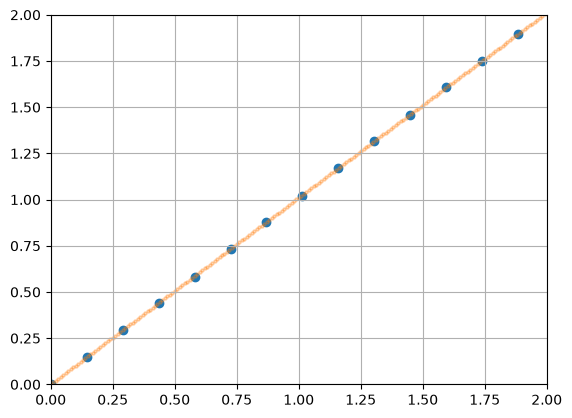

In [133]:
plt.scatter(x,y)
plt.scatter(xx,f(xx,c0,c1,c2,c3,c4), s=5, alpha=0.3)
plt.grid(True)
plt.xlim(0,2)
plt.ylim(0,2)

In [129]:
res3 = y-f(x,c0,c1,c2,c3,c4)
#print(res3)
print(np.mean(res3))

-1.8257973689475966e-09


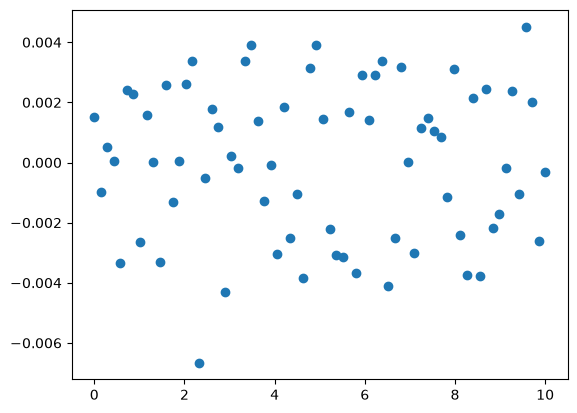

In [123]:
plt.scatter(x,res3)